# 2 — Tutorial: one molecule, end to end

A single system carried through the whole protocol in the order the article
presents it, so that each step can be inspected on its own. N₂ is the default;
changing `SYSTEM` in the geometry cell runs any of the six.

**This notebook recomputes everything from the geometry**, so it needs the
quantum-chemistry stack:

    pip install pyscf==2.14.0 qiskit==2.5.1 qiskit-nature==0.8.0 \
                qiskit-aer==0.17.2 qiskit-algorithms==0.4.0

Expect roughly a minute for N₂ and rather longer for the twenty-qubit systems.
To check the reported numbers without running any chemistry, use notebook 3
instead.

In [1]:
# --- repository root ---------------------------------------------------
# The notebooks live in notebooks/, the package in succd/, the data in data/.
# This cell finds the repository root (the folder holding pyproject.toml),
# makes it the working directory and puts it on sys.path, so that
# `from succd import ...` works without installing the package.
import os, sys
_d = os.path.abspath(os.getcwd())
while not os.path.isfile(os.path.join(_d, 'pyproject.toml')):
    if _d == os.path.dirname(_d):
        raise FileNotFoundError('repository root not found: expected a parent folder '
                                'holding pyproject.toml and succd/')
    _d = os.path.dirname(_d)
REPO = _d
os.environ['SUCCD_ROOT'] = REPO
os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)
from succd import paths            # data folders: paths.RESULTS, paths.VALUES, paths.SI ...
print('repository root:', os.path.basename(REPO), '(found and set as working directory)')


repository root: selected-uccd (found and set as working directory)


# N2, end to end, at delta = 3e-4

Every calculation the r15B documents report for N2, in the order it was run.  The other
five systems are carried in the geometry table below and any of them can be substituted by
changing one variable, but only N2 is executed here: it is small enough (16 qubits, 51
doubles) to finish on a laptop, and it is the system where the selection changes most
between the two thresholds (47 doubles at 2e-4, 39 at 3e-4).

**Runtime.** About 10-15 minutes on one core, dominated by the context build and the
variational optimisation. The heavy cells are marked.

## Environment

```
pip install pyscf==2.14.0 qiskit==2.5.1 qiskit-nature==0.8.0 qiskit-aer==0.17.2
```

`code/` must be importable — it holds the shipped pipeline (`selected_cc_pipeline.py`,
`PySCFDriver_mod_vers.py`, `pyscf_problem_extended.py`) plus the thin stage wrappers.
None of the physics is reimplemented in this notebook.

In [2]:
# qiskit-algorithms 0.4.0 has a circular import that fires on some installs
# when qiskit-nature first pulls it in. Importing this subpackage first makes
# solvers/__init__ run before abstract_ode_function, which resolves it.
# Harmless where the bug does not occur. See check_environment.py.
try:
    import qiskit_algorithms.time_evolvers.variational.solvers  # noqa: F401
except Exception:
    pass

import os, sys, json, time, math, warnings
warnings.filterwarnings('ignore')

ROOT = paths.ROOT

# The selection threshold. Everything downstream reads it from here.
DELTA = 3e-4
os.environ['SUCCD_DELTA'] = str(DELTA)

import numpy as np
from succd import core, drv
from succd import selected_cc_pipeline as scp

K = core.K                      # Hartree -> kcal/mol
print('delta   =', core.DELTA, 'Hartree  =', '%.4f kcal/mol' % (core.DELTA * K))
print('numpy   =', np.__version__)

delta   = 0.0003 Hartree  = 0.1883 kcal/mol
numpy   = 2.4.4


In [3]:
# ======================================================================
# GEOMETRIES — edit these freely. Angstrom. Whatever is written here is what
# gets computed: the cell below pushes it into the pipeline before anything
# runs. Add a system, delete one, move an atom, stretch a bond — all fine.
# The values below are the MP2/def2-SVP structures of the article.
# ======================================================================

GEOMETRIES = {

# H6
"H6": """H    -0.00000013033398  -0.00000027656978  -1.63585537349176
H    -0.00000002026762  -0.00000001049860  -0.88216228307366
H     0.00000005145092   0.00000026737096   2.12317470217342
H     0.00000019741506   0.00000028652252   2.87682413358394
H     0.00000001191796   0.00000000445340   5.88216389396856
H    -0.00000011018233  -0.00000027127849   6.63585492683949""",

# H8
"H8": """H     0.00000014047129   0.00000007179489  -2.49463655320066
H     0.00000005471022   0.00000003978284  -1.74094036515667
H    -0.00000000410940  -0.00000006874485   1.24863503981317
H    -0.00000012507223  -0.00000010066620   2.00229939584808
H    -0.00000019452856  -0.00000006736999   4.99770518795901
H    -0.00000012436358   0.00000002198468   5.75136984133156
H     0.00000006114635  -0.00000000235498   8.74093595148680
H     0.00000019174591   0.00000010557361   9.49463150191870""",

# N2
"N2": """N     0.00000000000000   0.00000000000000   0.03808486286764
N     0.00000000000000   0.00000000000000   1.16191513713236""",

# CO
"CO": """O    -1.07180221708728   0.00000000000000   0.00000000000000
C     0.07180221708728   0.00000000000000   0.00000000000000""",

# CH2O
"CH2O": """H     1.07578703937518  -0.14380969167056   1.05707279366277
C     0.59552162304750   0.01521281882427   0.06858835087804
H     1.27921938071923   0.20323734246116  -0.78595667392319
O    -0.61132804314190  -0.01554046961487  -0.07040447061762""",

# C2H2 (acetylene)
"C2H2": """C     0.59610628651506   0.01277743826555   0.14122987213962
C    -0.59608390436389  -0.01275984381194  -0.14117151138292
H     1.63992701862499   0.03514052846642   0.38864357314535
H    -1.63994940077616  -0.03505812292003  -0.38840193390205""",
}

# frozen core orbitals per system
FROZEN = {"H6": 0, "H8": 0, "N2": 2, "CO": 2, "CH2O": 2, "C2H2": 2}


In [4]:
# ======================================================================
# CHOOSE THE MOLECULE. Any key of GEOMETRIES above.
#     'H6'  'H8'  'N2'  'CO'  'CH2O'  'C2H2'
# ======================================================================
SYSTEM = 'N2'

# Push the geometry above into the pipeline. core.build() reads geoms.SYSTEMS,
# so replacing its contents is what makes an edit above take effect. This is
# the same mechanism notebooks 4 and 5 use.
from succd import geoms
geoms.SYSTEMS.clear()
geoms.SYSTEMS.update({k: (GEOMETRIES[k], FROZEN[k]) for k in GEOMETRIES})

# echo exactly what will be computed
import itertools, math
_rows = [l.split() for l in GEOMETRIES[SYSTEM].strip().split("\n") if l.strip()]
_lab  = [r[0] for r in _rows]
_xyz  = [[float(v) for v in r[1:4]] for r in _rows]
print(f"running {SYSTEM}   frozen core = {FROZEN[SYSTEM]}   atoms = {len(_lab)}")
for _l, _c in zip(_lab, _xyz):
    print("    %-3s %18.14f %18.14f %18.14f" % (_l, *_c))
_b = [(f"{_lab[i]}{i+1}-{_lab[j]}{j+1}", math.dist(_xyz[i], _xyz[j]))
      for i, j in itertools.combinations(range(len(_lab)), 2)
      if math.dist(_xyz[i], _xyz[j]) < 1.75]
if _b:
    print("    bonds:", "   ".join(f"{k} {d:.4f} A" for k, d in _b))

# the reference calculations further down build their own pyscf Mole,
# so give them the same edited geometry
xyz, nfrozen = GEOMETRIES[SYSTEM], FROZEN[SYSTEM]


running N2   frozen core = 2   atoms = 2
    N     0.00000000000000   0.00000000000000   0.03808486286764
    N     0.00000000000000   0.00000000000000   1.16191513713236
    bonds: N1-N2 1.1238 A


## Step 1 — build the union context  *(heavy: ~1 min for N2)*

`core.build` runs the modified PySCF driver, forms the active space, builds the doubles
manifold with its MP2 estimates, maps every excitation generator under Jordan-Wigner, and
where the symmetry allows it produces the Z2-tapered Hamiltonian matrix.  Everything after
this point reads from that one object, so the ranking, the circuit and the reference
energies cannot drift apart.

In [5]:
t0 = time.time()
CTX = core.build(SYSTEM)
print('\nbuilt in %.0f s' % (time.time() - t0))
print('spatial orbitals M      :', CTX['M'])
print('electrons (na, nb)      :', CTX['na'], CTX['nb'])
print('qubits (JW)             :', 2 * CTX['M'])
print('doubles in the manifold :', len(CTX['dbl']))
print('singles                 :', len(CTX['singles_idx']))
print('tapered matrix available:', CTX['_tap'])

Ades Reigns
Ades Reigns


Frozen Core informations: {'nuclear_repulsion_energy': np.float64(23.07259728524828), 'FreezeCoreTransformer': np.float64(-100.71362745139737)}
['1A', '2A', '3A', '4A', '5A', '6A', '7A', '8A', '1B', '2B', '3B', '4B', '5B', '6B', '7B', '8B']




 Other important parts for the problem created now.
        
        A. Number of spin orbitals is: 16
        B. The number of JW configuration is: 2^16 =  65536
        C. Hence the JW matrix is a: 16 x 16
        D. Occupied orbitals: 5
        E. Unoccupied orbitals: 3
         



Time for JW Mapping:  2.977628231048584 



Time for Tapering Symmerties:  1.4233949184417725 



Elimination of Useless column saved into: df2
Elimination of Useless column Active in df1


time for mapper NON TAPERING: 3.234733819961548



built in 15 s
spatial orbitals M      : 8
electrons (na, nb)      : 5 5
qubits (JW)             : 16
doubles in the manifold : 51
singles                 : 2
tapered matrix available: True


## Step 2 — perturbative selection

A double is retained when its second-order estimate exceeds `delta`.  The ranking is the
only thing the threshold touches, so N follows from the stored scores alone.

In [6]:
scores = np.sort(np.abs(CTX['dfr']['E2_i'].values))[::-1]
N = int((scores > DELTA).sum())
assert N == core.nsel(CTX)          # core.nsel prunes CTX['mapped'] in place
print('total doubles      :', len(scores))
print('N at delta = 2e-4  :', int((scores > 2e-4).sum()))
print('N at delta = 3e-4  :', N)

# Does the cut fall inside a degenerate shell?
gap = scores[N-1] - scores[N]
print('\nlast kept    |E2| = %.6e' % scores[N-1])
print('first dropped|E2| = %.6e' % scores[N])
print('gap at the cut    = %.3e Hartree   -> shell split: %s'
      % (gap, gap < 1e-12))

start selection
total doubles      : 51
N at delta = 2e-4  : 47
N at delta = 3e-4  : 39

last kept    |E2| = 3.457482e-04
first dropped|E2| = 2.452799e-04
gap at the cut    = 1.005e-04 Hartree   -> shell split: False


### Where the threshold bites

The selection curve shows how sharply N depends on delta, which is what makes a single
consistent threshold across both documents necessary in the first place.

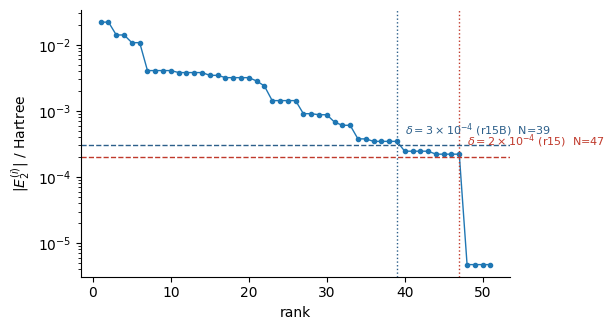

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.semilogy(np.arange(1, len(scores) + 1), scores, 'o-', ms=3, lw=1)
for d, c, l in ((2e-4, '#C0392B', r'$\delta=2\times10^{-4}$ (r15)'),
                (3e-4, '#2C5F8A', r'$\delta=3\times10^{-4}$ (r15B)')):
    n = int((scores > d).sum())
    ax.axhline(d, color=c, ls='--', lw=1)
    ax.axvline(n, color=c, ls=':', lw=1)
    ax.text(n + 1, d * 1.5, '%s  N=%d' % (l, n), color=c, fontsize=8)
ax.set_xlabel('rank'); ax.set_ylabel(r'$|E_2^{(i)}|$ / Hartree')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Step 3 — the three classical parameter sources

- `c_m` the s-CID coefficients, from diagonalising over the reference plus the N doubles
- `c'_m` the same divided by c0 (intermediate normalisation)
- `t_m` the converged s-CCD amplitudes
- `d_m` the closed-form rescaling of Eq. 5, `alpha_est = (2 - c0^2) / c0`, applied to c_m

Phases for all of them come from first-order Moller-Plesset signs.

In [8]:
P = core.params(CTX, N, False)
c0 = P['c0']
alpha_est = (2 - c0**2) / c0

print('c0            = %.6f' % c0)
print('alpha_est     = %.6f     (Eq. 5)' % alpha_est)
print('1/c0          = %.6f' % (1 / c0))
print('sum |c_i|     = %.6f' % P['sum_c'])
print('sum |t_i|     = %.6f' % P['sum_t'])
print('E_sCID        = %+.4f kcal/mol' % P['E_sCID'])
print('E_sCCD        = %+.4f kcal/mol' % P['E_sCCD'])

c0            = 0.964187
alpha_est     = 1.110098     (Eq. 5)
1/c0          = 1.037143
sum |c_i|     = 1.254559
sum |t_i|     = 1.374788
E_sCID        = -93.7532 kcal/mol
E_sCCD        = -99.6214 kcal/mol


## Step 4 — circuit energies

`core.evaluator` returns the expectation value of the Hamiltonian in the state the ansatz
prepares.  For a tapered system it works on the reduced matrix, so each call is fast; for
the 20-qubit systems it propagates the full Jordan-Wigner statevector instead and each call
costs about a minute.

In [9]:
Ev = core.evaluator(CTX)

E = {}
E['c_m']  = float(Ev(P['c'], N))
E['cp_m'] = float(Ev(P['cp'], N))
E['d_m']  = float(Ev(alpha_est * P['c'], N))
E['t_m']  = float(Ev(P['t'], N))

for k in ('c_m', 'cp_m', 'd_m', 't_m'):
    print('E_sUCCD(%-5s) = %+10.4f kcal/mol' % (k, E[k]))
print('\nE_sCCD          = %+10.4f' % P['E_sCCD'])
print("dE'(d_m)        = %+10.4f   (E_sCCD - E_sUCCD(d_m))" % (P['E_sCCD'] - E['d_m']))

E_sUCCD(c_m  ) =   -99.6524 kcal/mol
E_sUCCD(cp_m ) =  -100.2764 kcal/mol
E_sUCCD(d_m  ) =  -100.8869 kcal/mol
E_sUCCD(t_m  ) =  -100.8924 kcal/mol

E_sCCD          =   -99.6214
dE'(d_m)        =    +1.2654   (E_sCCD - E_sUCCD(d_m))


## Step 5 — the ray optimum and the variational optimum

`alpha*` is the best single scalar along the c_m direction; `p_m` is the best point in the
full N-dimensional parameter space.  The gap between `E(d_m)` and `E(p_m)` is what
Figure 5 plots.

*(heavy: the optimisation takes a couple of minutes for N2)*

In [10]:
from scipy.optimize import minimize, minimize_scalar

r = minimize_scalar(lambda a: Ev(a * P['c'], N), bracket=(1.0, 1.15),
                    method='brent', options={'xtol': 1e-6})
astar, E_astar = float(r.x), float(r.fun)
print('alpha*        = %.6f   E = %+.4f  (%d evaluations)' % (astar, E_astar, r.nfev))
print('alpha_est/alpha* = %.4f' % (alpha_est / astar))

gap = E_astar - E['c_m']
print('\nfraction of the ray gain recovered')
print('  by 1/c0      : %.3f' % ((E['cp_m'] - E['c_m']) / gap))
print('  by alpha_est : %.3f' % ((E['d_m']  - E['c_m']) / gap))

alpha*        = 1.128727   E = -100.9131  (10 evaluations)
alpha_est/alpha* = 0.9835

fraction of the ray gain recovered
  by 1/c0      : 0.495
  by alpha_est : 0.979


In [11]:
t0 = time.time()
opt = minimize(lambda p: Ev(p, N), P['c'], method='L-BFGS-B',
               options={'maxiter': 4000, 'ftol': 1e-13, 'gtol': 1e-9})
E_pm = float(opt.fun)
print('p_m from c_m start: %+.6f  (nit=%d, nfev=%d, %.0f s, converged=%s)'
      % (E_pm, opt.nit, opt.nfev, time.time() - t0, opt.success))

# Starting from t_m must land on the same optimum; that is the check that p_m is not an
# artefact of where the optimisation began.
opt2 = minimize(lambda p: Ev(p, N), P['t'], method='L-BFGS-B',
                options={'maxiter': 4000, 'ftol': 1e-13, 'gtol': 1e-9})
print('p_m from t_m start: %+.6f  (agreement %.2e)'
      % (opt2.fun, abs(opt2.fun - E_pm)))

print('\nresiduals against the variational optimum (Figure 5):')
for k in ('c_m', 'd_m', 't_m'):
    print('  %-5s : %8.4f kcal/mol' % (k, E[k] - E_pm))

p_m from c_m start: -100.963803  (nit=22, nfev=1520, 62 s, converged=True)


p_m from t_m start: -100.963803  (agreement 2.46e-09)

residuals against the variational optimum (Figure 5):
  c_m   :   1.3114 kcal/mol
  d_m   :   0.0769 kcal/mol
  t_m   :   0.0714 kcal/mol


## Step 6 — the surplus is the quadruples

The s-CID space holds only the reference and the N doubles.  The circuit reaches
quadruples through the bilinear terms of the product, at no extra operator or depth cost.
Building the reference + doubles + quadruples space explicitly and diagonalising it must
reproduce the same correlation energy — this is Figure 6, and it needs no circuit.

In [12]:
from pyscf.fci import direct_spin1, cistring
from scipy.sparse.linalg import LinearOperator, eigsh

HFa, HFb = int(CTX['HFdet'][0]), int(CTX['HFdet'][1])
dd = [(int(d[0]), int(d[1])) for d in CTX['double_dets'][:N]]
ops = [((HFa & ~Da), (Da & ~HFa), (HFb & ~Db), (Db & ~HFb)) for Da, Db in dd]

def apply(op, D):
    ra, aa, rb, ab = op
    Da, Db = D
    if (Da & ra) != ra or (Da & aa) or (Db & rb) != rb or (Db & ab):
        return None
    return ((Da & ~ra) | aa, (Db & ~rb) | ab)

quads = set()
for i in range(N):
    for j in range(i + 1, N):
        R = apply(ops[i], dd[j])
        if R and ((HFa ^ R[0]).bit_count() + (HFb ^ R[1]).bit_count()) // 2 >= 4:
            quads.add(R)

M, na, nb = CTX['M'], CTX['na'], CTX['nb']
nstr = cistring.num_strings(M, na)
h2e = direct_spin1.absorb_h1e(CTX['h1'], CTX['eri'], M, (na, nb), .5)
dets = [(HFa, HFb)] + dd + sorted(quads)
addr = np.unique([cistring.str2addr(M, na, x) * nstr + cistring.str2addr(M, nb, y)
                  for x, y in dets])

def mv(x):
    v = np.zeros(nstr * nstr); v[addr] = x
    return direct_spin1.contract_2e(h2e, v.reshape(nstr, nstr), M, (na, nb)).ravel()[addr]

lam = eigsh(LinearOperator((len(addr),) * 2, matvec=mv, dtype=float), k=1,
            which='SA', tol=1e-11, maxiter=60000)[0][0]
E_DQ = float((lam + CTX['shift']) * K)

surplus_t = abs(E['t_m'] - P['E_sCID'])
surplus_q = abs(E_DQ - P['E_sCID'])
print('N_Q                         = %d' % len(quads))
print('circuit surplus over s-CID  = %.4f kcal/mol' % surplus_t)
print('explicit D+Q surplus        = %.4f kcal/mol' % surplus_q)
print('agreement                   = %.1f %%' % (100 * surplus_t / surplus_q))

N_Q                         = 128
circuit surplus over s-CID  = 7.1392 kcal/mol
explicit D+Q surplus        = 7.4265 kcal/mol
agreement                   = 96.1 %


## Step 7 — reference energies

FCI in the same active space, and the unselected CISD and CCSD used by the Appendix.

In [13]:
from pyscf import gto, scf, cc, ci

lamF, _ = direct_spin1.kernel(CTX['h1'], CTX['eri'], M, (na, nb), conv_tol=1e-13)
E_FCI = float((lamF + CTX['shift']) * K)

mol = gto.M(atom=xyz, basis='sto-6g', verbose=0)
mf = scf.RHF(mol).run()
E_CCSD = float(cc.CCSD(mf, frozen=nfrozen).run().e_corr * K)
E_CISD = float(ci.CISD(mf, frozen=nfrozen).run().e_corr * K)

# Eq. 10: the circuit's surplus repairs the size-extensivity defect of CISD
E_enh = E_CISD + (E['d_m'] - P['E_sCID'])
print('FCI            = %+10.4f' % E_FCI)
print('CISD           = %+10.4f   (dev %+.4f)' % (E_CISD, E_CISD - E_FCI))
print('Enhanced(d_m)  = %+10.4f   (dev %+.4f)' % (E_enh,  E_enh  - E_FCI))
print('CCSD           = %+10.4f   (dev %+.4f)' % (E_CCSD, E_CCSD - E_FCI))

FCI            =  -104.4077
CISD           =   -95.5056   (dev +8.9021)
Enhanced(d_m)  =  -102.6393   (dev +1.7684)
CCSD           =  -101.6133   (dev +2.7944)


## Step 8 — circuit cost

s-UCCD carries the N selected doubles; UCCSD carries every mappable excitation of the same
active space.  One identical synthesis is applied to both, so the ratio is structural.

Two traps live here, and both produced wrong numbers before they were caught:

1. `core.nsel` **prunes `CTX['mapped']` in place**, so after selection the "full" doubles
   list is the selected one. The full pool must be read before, or taken from `em_jw`.
2. The full UCCSD pool is `em_jw`, the complete excitation list — *not* the MP2
   pre-screened doubles in `dfr`. The two coincide for H6 and H8, which is exactly why
   those two matched while the frozen-core diatomics did not.

In [14]:
from qiskit import transpile
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit_nature.second_q.circuit.library import HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper

def build_circuit(ctx, ops):
    hf = HartreeFock(ctx['M'], ctx['npart'], JordanWignerMapper())
    qc = QuantumCircuit(hf.num_qubits)
    qc.compose(hf, inplace=True)
    for op in ops:
        qc.append(PauliEvolutionGate(op, time=0.1), range(hf.num_qubits))
    return qc

def counts(qc):
    t = transpile(qc, basis_gates=['cx', 'rz', 'sx', 'x'],
                  optimization_level=1, seed_transpiler=7)
    d = dict(t.count_ops())
    return dict(depth=t.depth(), cx=d.get('cx', 0), total=sum(d.values()))

em, mp = CTX['em_jw'], CTX['mapped']
sel_ops  = [em[mp[k]] for k in range(N)]     # mapped is already pruned to the N kept
full_ops = [o for o in em if o is not None]  # the complete pool

c_sel, c_full = counts(build_circuit(CTX, sel_ops)), counts(build_circuit(CTX, full_ops))
print('s-UCCD  N=%3d  CX=%6d  total=%6d  depth=%6d' % (N, c_sel['cx'], c_sel['total'], c_sel['depth']))
print('UCCSD   n=%3d  CX=%6d  total=%6d  depth=%6d' % (len(full_ops), c_full['cx'], c_full['total'], c_full['depth']))
print('\nCX reduction  = %.2f x' % (c_full['cx'] / c_sel['cx']))
print('CX per double = %.1f' % (c_sel['cx'] / N))

s-UCCD  N= 39  CX=  4652  total=  7031  depth=  5232
UCCSD   n=315  CX= 34260  total= 51558  depth= 41691

CX reduction  = 7.36 x
CX per double = 119.3


## Step 9 — the SQD noise condition (Eq. 11)

A configuration of weight w is visible above the depolarised background when
`p w >= (1-p)/D`.  The binding configuration is the weakest one still needed to reach 95 %
of the correlation energy of the populated space, so the required survival probability is
`1/(1 + D w_min)` and the admitted two-qubit count is `ln(p)/ln(f)`.

In [15]:
from math import comb

FIDELITY = 0.9977
psi = core.state(CTX, alpha_est * P['c'])
w = np.abs(psi) ** 2; w /= w.sum()

mask = (1 << M) - 1
idx = [i for i in np.where(w > 1e-14)[0]
       if bin(int(i) & mask).count('1') == na and bin((int(i) >> M) & mask).count('1') == nb]
order = sorted(idx, key=lambda i: -w[i])

def subspace_energy(sub):
    a = np.unique([cistring.str2addr(M, na, int(i) & mask) * nstr +
                   cistring.str2addr(M, nb, (int(i) >> M) & mask) for i in sub])
    def mv2(x):
        v = np.zeros(nstr * nstr); v[a] = x
        return direct_spin1.contract_2e(h2e, v.reshape(nstr, nstr), M, (na, nb)).ravel()[a]
    l = eigsh(LinearOperator((len(a),) * 2, matvec=mv2, dtype=float), k=1,
              which='SA', tol=1e-10, maxiter=40000)[0][0]
    return float((l + CTX['shift']) * K)

target = 0.95 * subspace_energy(order)
lo, hi = 1, len(order)
while lo < hi:
    mid = (lo + hi) // 2
    if subspace_energy(order[:mid]) <= target: hi = mid
    else: lo = mid + 1

w_min = float(w[order[lo - 1]])
D = comb(M, na) * comb(M, nb)
p_req = 1.0 / (1.0 + D * w_min)
N_CX = math.floor(math.log(p_req) / math.log(FIDELITY))

print('determinants for 95 %% : %d of %d populated' % (lo, len(order)))
print('sector dimension D    : %d' % D)
print('w_min                 : %.4e' % w_min)
print('D w_min               : %.4f' % (D * w_min))
print('required p            : %.4f' % p_req)
print('admitted N_CX         : %d' % N_CX)
print('\ncircuit actually needs %d CX -> condition %s'
      % (c_sel['cx'], 'satisfied' if c_sel['cx'] <= N_CX else 'violated'))

determinants for 95 % : 48 of 220 populated
sector dimension D    : 3136
w_min                 : 7.7674e-05
D w_min               : 0.2436
required p            : 0.8041
admitted N_CX         : 94

circuit actually needs 4652 CX -> condition violated


## Step 10 — validity domain under bond stretching

The whole procedure repeats from scratch at each geometry: new selection, new c0, new
alpha_est, new s-CCD solution, and a fresh Brent search for alpha*.  The prediction is
always scored against the optimum it is meant to reproduce at that geometry.

*(heavy: about half a minute per point)*

In [16]:
def scan_point(dist):
    ctx = scp.build_union_context('N 0 0 0; N 0 0 %.6f' % dist, basis='sto-6g',
                                  n_frozen=2, verbose=False)
    ctx['_tap'] = (ctx.get('Hmat') is not None and ctx.get('gens_tap') is not None)
    n = core.nsel(ctx)
    ev = core.evaluator(ctx)
    sg = np.sign(ctx['dfr']['t_mp'].values[:n]).astype(float)
    _, vec = scp.ci_corr([ctx['HFdet']] + ctx['double_dets'][:n], ctx['h1'], ctx['eri'])
    c0_ = abs(vec[0]); cm = np.abs(vec[1:1 + n])
    a_cl = (2 - c0_**2) / c0_
    rr = minimize_scalar(lambda a: ev(a * cm * sg, n), bracket=(1.0, 1.2),
                         method='brent', options={'xtol': 1e-6})
    return dict(R=dist, N=n, c0=c0_, astar=float(rr.x), a_est=a_cl,
                penalty=float(ev(a_cl * cm * sg, n) - rr.fun))

SCAN = [1.10, 1.30, 1.50, 1.70]     # add 1.90, 2.10, 2.40 to see the breakdown
rows = []
for d in SCAN:
    r = scan_point(d); rows.append(r)
    print('R=%.2f  N=%3d  c0=%.4f  alpha*=%.4f  alpha_est=%.4f  penalty=%8.3f'
          % (r['R'], r['N'], r['c0'], r['astar'], r['a_est'], r['penalty']))

Ades Reigns


Frozen Core informations: {'nuclear_repulsion_energy': np.float64(23.572439395527272), 'FreezeCoreTransformer': np.float64(-100.95861830041508)}
['1A', '2A', '3A', '4A', '5A', '6A', '7A', '8A', '1B', '2B', '3B', '4B', '5B', '6B', '7B', '8B']




 Other important parts for the problem created now.
        
        A. Number of spin orbitals is: 16
        B. The number of JW configuration is: 2^16 =  65536
        C. Hence the JW matrix is a: 16 x 16
        D. Occupied orbitals: 5
        E. Unoccupied orbitals: 3
         



Time for JW Mapping:  3.424506187438965 



Time for Tapering Symmerties:  1.3952128887176514 



Elimination of Useless column saved into: df2
Elimination of Useless column Active in df1


time for mapper NON TAPERING: 2.99094557762146


... (18 outputs left out)

Elimination of Useless column saved into: df2
Elimination of Useless column Active in df1


time for mapper NON TAPERING: 2.996703624725342


start selection


R=1.70  N= 39  c0=0.8229  alpha*=1.1831  alpha_est=1.6074  penalty=  16.421


## Summary

Everything the documents report for N2, collected in one place and compared against the
stored result file so a re-run can be checked immediately.

In [17]:
summary = dict(
    system=SYSTEM, delta=DELTA, N=N, c0=c0, alpha_est=alpha_est, alpha_star=astar,
    E_sCID=P['E_sCID'], E_sCCD=P['E_sCCD'], E_FCI=E_FCI,
    E_cm=E['c_m'], E_cpm=E['cp_m'], E_dm=E['d_m'], E_tm=E['t_m'], E_pm=E_pm,
    N_Q=len(quads), E_DQ=E_DQ, quad_agreement_pct=100 * surplus_t / surplus_q,
    cx_sUCCD=c_sel['cx'], cx_UCCSD=c_full['cx'], cx_per_double=c_sel['cx'] / N,
    dets_95=lo, populated=len(order), D=D, w_min=w_min, N_CX_admitted=N_CX,
    E_CISD=E_CISD, E_CCSD=E_CCSD, E_enhanced=E_enh)

for k, v in summary.items():
    print('%-22s %s' % (k, ('%.6f' % v) if isinstance(v, float) else v))

stored_path = paths.results('res_%s.json' % SYSTEM)
if os.path.exists(stored_path):
    S = json.load(open(stored_path))
    print('\ncomparison with the stored run:')
    for label, here, there in (
            ('N',        N,          S['meta']['n']),
            ('c0',       c0,         S['meta']['c0']),
            ('E_sCID',   P['E_sCID'],S['meta']['E_sCID']),
            ('E_dm',     E['d_m'],   S['D_dm']['var']),
            ('E_tm',     E['t_m'],   S['D_t']['var']),
            ('alpha*',   astar,      S['alpha']['astar']),
            ('N_Q',      len(quads), S['quad']['NQ'])):
        d = abs(here - there)
        print('  %-8s here=%-14s stored=%-14s  |diff|=%.2e %s'
              % (label, '%.6f' % here if isinstance(here, float) else here,
                 '%.6f' % there if isinstance(there, float) else there,
                 d, 'OK' if d < 1e-4 else 'CHECK'))

system                 N2
delta                  0.000300
N                      39
c0                     0.964187
alpha_est              1.110098
alpha_star             1.128727
E_sCID                 -93.753152
E_sCCD                 -99.621411
E_FCI                  -104.407689
E_cm                   -99.652433
E_cpm                  -100.276412
E_dm                   -100.886854
E_tm                   -100.892396
E_pm                   -100.963803
N_Q                    128
E_DQ                   -101.179699
quad_agreement_pct     96.131406
cx_sUCCD               4652
cx_UCCSD               34260
cx_per_double          119.282051
dets_95                48
populated              220
D                      3136
w_min                  0.000078
N_CX_admitted          94
E_CISD                 -95.505580
E_CCSD                 -101.613251
E_enhanced             -102.639283

comparison with the stored run:
  N        here=39             stored=39              |diff|=0.00e+00 OK
  c0    